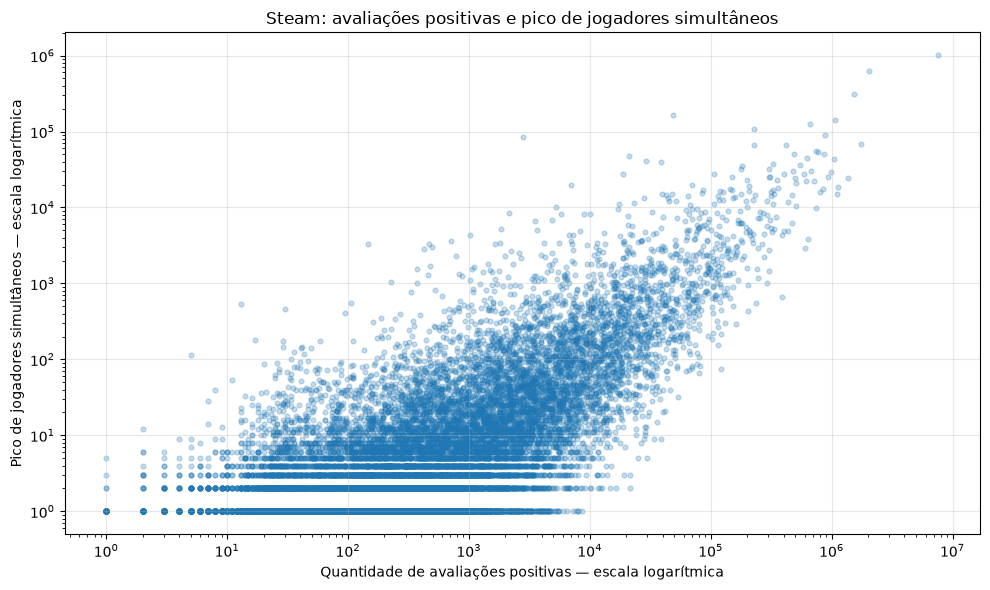

In [1]:
import polars as pl
import matplotlib.pyplot as plt

df_dispersao = (
    pl.scan_parquet("steam_2026_organizada_PANDAS.parquet")
    .select(
        "Avaliações positivas",
        "Pico de jogadores simultâneos"
    )
    .filter(
        (pl.col("Avaliações positivas") > 0)
        & (pl.col("Pico de jogadores simultâneos") > 0)
    )
    .collect()
)

plt.figure(figsize=(10, 6))

plt.scatter(
    df_dispersao["Avaliações positivas"].to_numpy(),
    df_dispersao["Pico de jogadores simultâneos"].to_numpy(),
    alpha=0.25,
    s=12
)

plt.xscale("log")
plt.yscale("log")

plt.title("Steam: avaliações positivas e pico de jogadores simultâneos")
plt.xlabel("Quantidade de avaliações positivas — escala logarítmica")
plt.ylabel("Pico de jogadores simultâneos — escala logarítmica")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()